무드별로 K-Means 군집화

- Feature 6개를 StandardScaler로 표준화
- 무드마다 K=2~6을 비교한 뒤 K=3으로 고정

In [31]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from IPython.display import display

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)

In [33]:
df = pd.read_csv("../data/processed/tracks_with_mood.csv")

print(df.shape)
df.head()

(76630, 16)


,track_id,track_name,artists,album_name,track_genre,duration_ms,popularity,danceability,energy,tempo,acousticness,instrumentalness,valence,mood,mood_score,mood_gap
0,5SuOikwiRyPMVoIQDJUgSV,Comedy,Gen Hoshino,Comedy,acoustic,230666,73,0.676,0.461,87.917,0.032,0.000,0.715,romantic,0.595,0.001
1,4qPNDBW1i3p13qLCt0Ki3A,Ghost - Acoustic,Ben Woodward,Ghost (Acoustic),acoustic,149610,55,0.420,0.166,77.489,0.924,0.000,0.267,chill,0.918,0.071
2,1iJBSr7s7jYXzM8EGcbK5b,To Begin Again,Ingrid Michaelson;ZAYN,To Begin Again,acoustic,210826,57,0.438,0.359,76.332,0.210,0.000,0.120,sad,0.828,0.055
3,6lfxq3CG4xtTiEg7opyCyx,Can't Help Falling In Love,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,acoustic,201933,71,0.266,0.060,181.740,0.905,0.000,0.143,dreamy,0.831,0.001
4,5vjLSffimiIP26QG5WcN2K,Hold On,Chord Overstreet,Hold On,acoustic,198853,82,0.618,0.443,119.949,0.469,0.000,0.167,sad,0.767,0.138


In [34]:
features = ["danceability", "energy", "tempo", "acousticness", "instrumentalness", "valence"]

df["mood"].value_counts()

mood
happy        21405
energetic    16643
sad          15354
chill         7644
focus         6456
romantic      5051
dreamy        4077
Name: count, dtype: int64

In [35]:
print(df[features].isna().sum())
print(df["mood"].isna().sum())
print(df["mood"].nunique())

danceability        0
energy              0
tempo               0
acousticness        0
instrumentalness    0
valence             0
dtype: int64
0
7


In [36]:
df.groupby("mood")[features].mean().round(3)

,danceability,energy,tempo,acousticness,instrumentalness,valence
mood,,,,,,
chill,0.478,0.378,88.921,0.641,0.102,0.392
dreamy,0.427,0.306,141.432,0.826,0.316,0.385
energetic,0.555,0.880,140.938,0.068,0.150,0.391
focus,0.406,0.602,123.105,0.371,0.663,0.313
happy,0.673,0.750,124.978,0.211,0.061,0.766
romantic,0.627,0.507,104.734,0.639,0.028,0.685
sad,0.539,0.490,115.950,0.387,0.165,0.207


#### Feature 표준화

In [37]:
scaler = StandardScaler()

scaled_values = scaler.fit_transform(df[features])

scaled_df = pd.DataFrame(scaled_values, columns=features, index=df.index)

scaled_df.head()

,danceability,energy,tempo,acousticness,instrumentalness,valence
0,0.657,-0.684,-1.153,-0.886,-0.525,0.934
1,-0.822,-1.831,-1.501,1.745,-0.525,-0.783
2,-0.718,-1.080,-1.540,-0.361,-0.525,-1.347
3,-1.712,-2.244,1.982,1.689,-0.525,-1.258
4,0.322,-0.754,-0.083,0.403,-0.525,-1.167


#### K값 비교용 함수

In [38]:
def get_cluster_scores(data, k):
    model = KMeans(n_clusters=k, init="k-means++", n_init=20, max_iter=300, random_state=42)

    labels = model.fit_predict(data)

    return {"inertia": model.inertia_, "silhouette": silhouette_score(data, labels)}

#### 무드별 K값 비교

In [39]:
results = []

for mood in sorted(df["mood"].unique()):
    mood_index = df["mood"] == mood
    mood_data = scaled_df.loc[mood_index, features]

    for k in range(2, 7):
        scores = get_cluster_scores(mood_data, k)

        results.append(
            {"mood": mood, "k": k, "inertia": scores["inertia"], "silhouette": scores["silhouette"]}
        )

cluster_results = pd.DataFrame(results)

cluster_results

,mood,k,inertia,silhouette
0,chill,2,18484.924,0.268
1,chill,3,13341.029,0.309
2,chill,4,10996.619,0.275
3,chill,5,9934.015,0.282
4,chill,6,8996.594,0.245
5,dreamy,2,10195.169,0.417
6,dreamy,3,8600.285,0.277
7,dreamy,4,7598.322,0.266
8,dreamy,5,6660.152,0.233
9,dreamy,6,6031.510,0.227


#### K값별 Silhouette Score

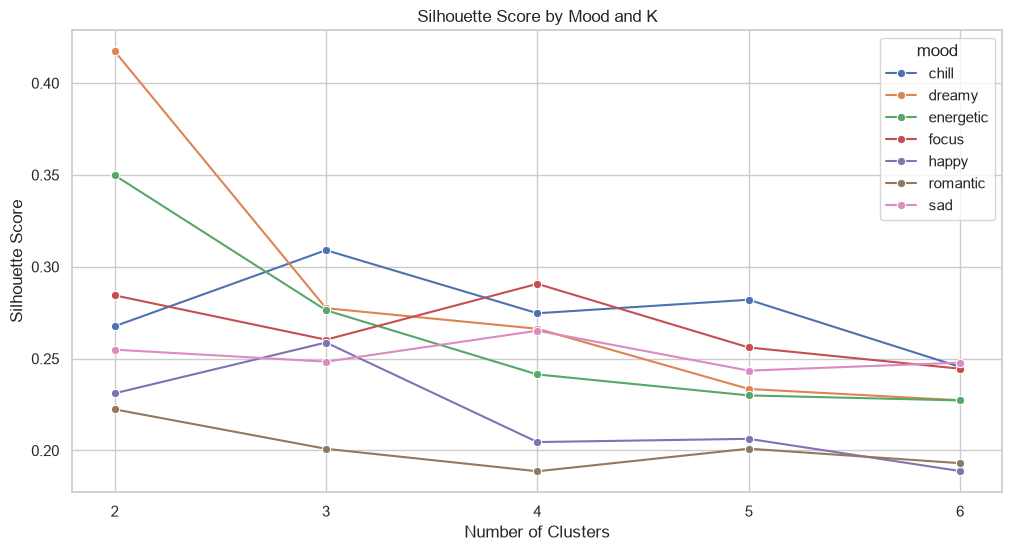

In [40]:
plt.figure(figsize=(12, 6))

sns.lineplot(data=cluster_results, x="k", y="silhouette", hue="mood", marker="o")

plt.title("Silhouette Score by Mood and K")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 7))
plt.show()

#### K값별 Inertia

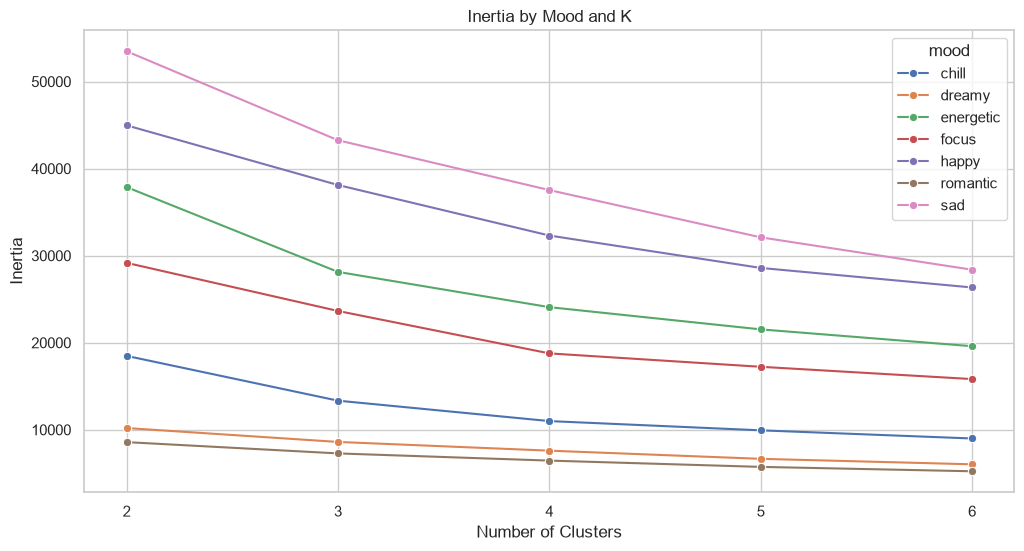

In [41]:
plt.figure(figsize=(12, 6))

sns.lineplot(data=cluster_results, x="k", y="inertia", hue="mood", marker="o")

plt.title("Inertia by Mood and K")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(range(2, 7))
plt.show()

#### 무드별 Silhouette 최고 K 확인

In [42]:
best_k_by_mood = (
    cluster_results.sort_values(["mood", "silhouette"], ascending=[True, False])
    .groupby("mood")
    .first()
    .reset_index()
)

best_k_by_mood

,mood,k,inertia,silhouette
0,chill,3,13341.029,0.309
1,dreamy,2,10195.169,0.417
2,energetic,2,37871.641,0.350
3,focus,4,18773.201,0.291
4,happy,3,38115.302,0.259
5,romantic,2,8578.279,0.222
6,sad,4,37532.688,0.265


In [43]:
best_k_by_mood[["mood", "k", "silhouette", "inertia"]]

,mood,k,silhouette,inertia
0,chill,3,0.309,13341.029
1,dreamy,2,0.417,10195.169
2,energetic,2,0.350,37871.641
3,focus,4,0.291,18773.201
4,happy,3,0.259,38115.302
5,romantic,2,0.222,8578.279
6,sad,4,0.265,37532.688


#### 기본 군집 수 설정

In [44]:
n_clusters = 3

print(f"최종 군집 수: {n_clusters}")

최종 군집 수: 3


#### 무드별 K-Means

In [45]:
df["cluster"] = -1

models = {}

for mood in sorted(df["mood"].unique()):
    mood_index = df["mood"] == mood
    mood_data = scaled_df.loc[mood_index, features]

    model = KMeans(
        n_clusters=n_clusters, init="k-means++", n_init=20, max_iter=300, random_state=42
    )

    labels = model.fit_predict(mood_data)

    df.loc[mood_index, "cluster"] = labels
    models[mood] = model

df["cluster"] = df["cluster"].astype(int)

df[["track_name", "mood", "cluster"]].head(10)

,track_name,mood,cluster
0,Comedy,romantic,2
1,Ghost - Acoustic,chill,0
2,To Begin Again,sad,0
3,Can't Help Falling In Love,dreamy,2
4,Hold On,sad,1
5,Days I Will Remember,romantic,1
6,Say Something,sad,1
7,I'm Yours,happy,1
8,Lucky,romantic,0
9,Hunger,sad,0


In [46]:
df["mood_cluster"] = df["mood"] + "_" + df["cluster"].astype(str)

df["mood_cluster"].value_counts().sort_index()

mood_cluster
chill_0         4033
chill_1         2790
chill_2          821
dreamy_0        1344
dreamy_1        1385
dreamy_2        1348
energetic_0     7562
energetic_1     6339
energetic_2     2742
focus_0         1439
focus_1         2176
focus_2         2841
happy_0        13316
happy_1         6618
happy_2         1471
romantic_0      1488
romantic_1      1715
romantic_2      1848
sad_0           7668
sad_1           5032
sad_2           2654
Name: count, dtype: int64

#### 무드·군집별 곡 수

In [47]:
cluster_counts = df.groupby(["mood", "cluster"]).size().reset_index(name="track_count")

cluster_counts

,mood,cluster,track_count
0,chill,0,4033
1,chill,1,2790
2,chill,2,821
3,dreamy,0,1344
4,dreamy,1,1385
5,dreamy,2,1348
6,energetic,0,7562
7,energetic,1,6339
8,energetic,2,2742
9,focus,0,1439


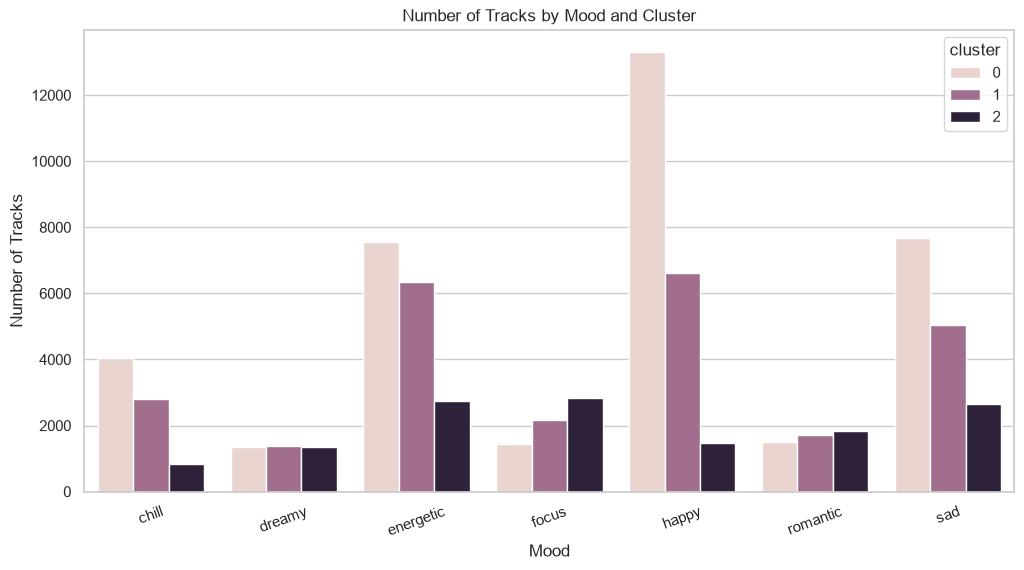

In [48]:
plt.figure(figsize=(12, 6))

sns.barplot(data=cluster_counts, x="mood", y="track_count", hue="cluster")

plt.title("Number of Tracks by Mood and Cluster")
plt.xlabel("Mood")
plt.ylabel("Number of Tracks")
plt.xticks(rotation=20)
plt.show()

#### 군집별 원본 Feature 평균

In [49]:
cluster_summary = df.groupby(["mood", "cluster"])[features].mean().round(3)

cluster_summary

danceability  energy   tempo  acousticness  \
mood      cluster                                               
chill     0               0.464   0.306  92.067         0.819   
          1               0.528   0.558  88.975         0.304   
          2               0.378   0.124  73.278         0.909   
dreamy    0               0.524   0.382 131.026         0.818   
          1               0.375   0.120 126.284         0.966   
          2               0.384   0.420 167.372         0.690   
energetic 0               0.640   0.850 125.273         0.100   
          1               0.433   0.907 160.096         0.048   
          2               0.602   0.899 139.853         0.025   
focus     0               0.296   0.259 113.837         0.858   
          1               0.588   0.527 130.431         0.445   
          2               0.321   0.832 122.187         0.069   
happy     0               0.711   0.747 110.110         0.198   
          1               0.593   0.754 155.047         0.261   
          2               0.692   0.762 124.291         0.099   
romantic  0               0.588   0.423 129.585         0.744   
          1               0.727   0.415  98.000         0.673   
          2               0.565   0.661  90.974         0.521   
sad       0               0.555   0.623 117.387         0.145   
          1               0.520   0.354 120.648         0.712   
          2               0.527   0.366 102.891         0.472   

                   instrumentalness  valence  
mood      cluster                             
chill     0                   0.012    0.374  
          1                   0.017    0.461  
          2                   0.834    0.245  
dreamy    0                   0.081    0.498  
          1                   0.835    0.253  
          2                   0.018    0.407  
energetic 0                   0.025    0.428  
          1                   0.038    0.381  
          2                   0.757    0.311  
focus     0                   0.919    0.159  
          1                   0.628    0.506  
          2                   0.562    0.242  
happy     0                   0.011    0.752  
          1                   0.011    0.792  
          2                   0.743    0.770  
romantic  0                   0.001    0.658  
          1                   0.077    0.730  
          2                   0.004    0.664  
sad       0                   0.035    0.232  
          1                   0.018    0.216  
          2                   0.821    0.121

#### 군집별 표준화 Feature 평균

In [50]:
scaled_with_labels = scaled_df.copy()

scaled_with_labels["mood"] = df["mood"]
scaled_with_labels["cluster"] = df["cluster"]

scaled_cluster_summary = scaled_with_labels.groupby(["mood", "cluster"])[features].mean().round(3)

scaled_cluster_summary

danceability  energy  tempo  acousticness  \
mood      cluster                                              
chill     0              -0.568  -1.288 -1.014         1.436   
          1              -0.196  -0.307 -1.117        -0.084   
          2              -1.064  -1.993 -1.642         1.701   
dreamy    0              -0.223  -0.990  0.287         1.432   
          1              -1.083  -2.009  0.129         1.870   
          2              -1.030  -0.842  1.502         1.055   
energetic 0               0.446   0.827  0.095        -0.685   
          1              -0.748   1.050  1.259        -0.839   
          2               0.229   1.019  0.582        -0.907   
focus     0              -1.539  -1.469 -0.287         1.551   
          1               0.149  -0.428  0.268         0.331   
          2              -1.392   0.760 -0.008        -0.778   
happy     0               0.857   0.427 -0.411        -0.397   
          1               0.178   0.455  1.090        -0.210   
          2               0.747   0.488  0.062        -0.689   
romantic  0               0.150  -0.832  0.239         1.214   
          1               0.953  -0.862 -0.816         1.006   
          2               0.016   0.095 -1.051         0.556   
sad       0              -0.042  -0.055 -0.168        -0.552   
          1              -0.244  -1.100 -0.059         1.118   
          2              -0.206  -1.053 -0.652         0.410   

                   instrumentalness  valence  
mood      cluster                             
chill     0                  -0.489   -0.373  
          1                  -0.472   -0.041  
          2                   2.088   -0.868  
dreamy    0                  -0.270    0.102  
          1                   2.092   -0.839  
          2                  -0.469   -0.245  
energetic 0                  -0.448   -0.166  
          1                  -0.407   -0.345  
          2                   1.845   -0.615  
focus     0                   2.354   -1.197  
          1                   1.442    0.135  
          2                   1.234   -0.880  
happy     0                  -0.490    1.076  
          1                  -0.492    1.229  
          2                   1.802    1.146  
romantic  0                  -0.521    0.716  
          1                  -0.284    0.991  
          2                  -0.514    0.737  
sad       0                  -0.416   -0.919  
          1                  -0.468   -0.980  
          2                   2.048   -1.341

In [51]:
for mood in sorted(df["mood"].unique()):
    print(f"\n[{mood}]")
    display(cluster_summary.loc[mood])


[chill]


,danceability,energy,tempo,acousticness,instrumentalness,valence
cluster,,,,,,
0,0.464,0.306,92.067,0.819,0.012,0.374
1,0.528,0.558,88.975,0.304,0.017,0.461
2,0.378,0.124,73.278,0.909,0.834,0.245



[dreamy]


,danceability,energy,tempo,acousticness,instrumentalness,valence
cluster,,,,,,
0,0.524,0.382,131.026,0.818,0.081,0.498
1,0.375,0.120,126.284,0.966,0.835,0.253
2,0.384,0.420,167.372,0.690,0.018,0.407



[energetic]


...

,danceability,energy,tempo,acousticness,instrumentalness,valence
cluster,,,,,,
0,0.711,0.747,110.110,0.198,0.011,0.752
1,0.593,0.754,155.047,0.261,0.011,0.792
2,0.692,0.762,124.291,0.099,0.743,0.770



[romantic]


,danceability,energy,tempo,acousticness,instrumentalness,valence
cluster,,,,,,
0,0.588,0.423,129.585,0.744,0.001,0.658
1,0.727,0.415,98.000,0.673,0.077,0.730
2,0.565,0.661,90.974,0.521,0.004,0.664



[sad]


,danceability,energy,tempo,acousticness,instrumentalness,valence
cluster,,,,,,
0,0.555,0.623,117.387,0.145,0.035,0.232
1,0.520,0.354,120.648,0.712,0.018,0.216
2,0.527,0.366,102.891,0.472,0.821,0.121


#### 무드별 군집 중심 확인

In [52]:
cluster_centers = []

for mood, model in models.items():
    centers = pd.DataFrame(scaler.inverse_transform(model.cluster_centers_), columns=features)

    centers["mood"] = mood
    centers["cluster"] = range(n_clusters)

    cluster_centers.append(centers)

cluster_centers = pd.concat(cluster_centers, ignore_index=True)

cluster_centers = cluster_centers[["mood", "cluster", *features]]

cluster_centers.round(3)

,mood,cluster,danceability,energy,tempo,acousticness,instrumentalness,valence
0,chill,0,0.464,0.306,92.055,0.819,0.012,0.374
1,chill,1,0.529,0.558,88.989,0.304,0.017,0.461
2,chill,2,0.378,0.124,73.278,0.909,0.834,0.245
3,dreamy,0,0.524,0.382,131.026,0.818,0.081,0.498
4,dreamy,1,0.375,0.120,126.284,0.966,0.835,0.253
5,dreamy,2,0.384,0.420,167.372,0.690,0.018,0.407
6,energetic,0,0.640,0.850,125.279,0.100,0.025,0.428
7,energetic,1,0.433,0.907,160.087,0.048,0.038,0.381
8,energetic,2,0.602,0.899,139.844,0.025,0.757,0.311
9,focus,0,0.296,0.259,113.906,0.858,0.919,0.160


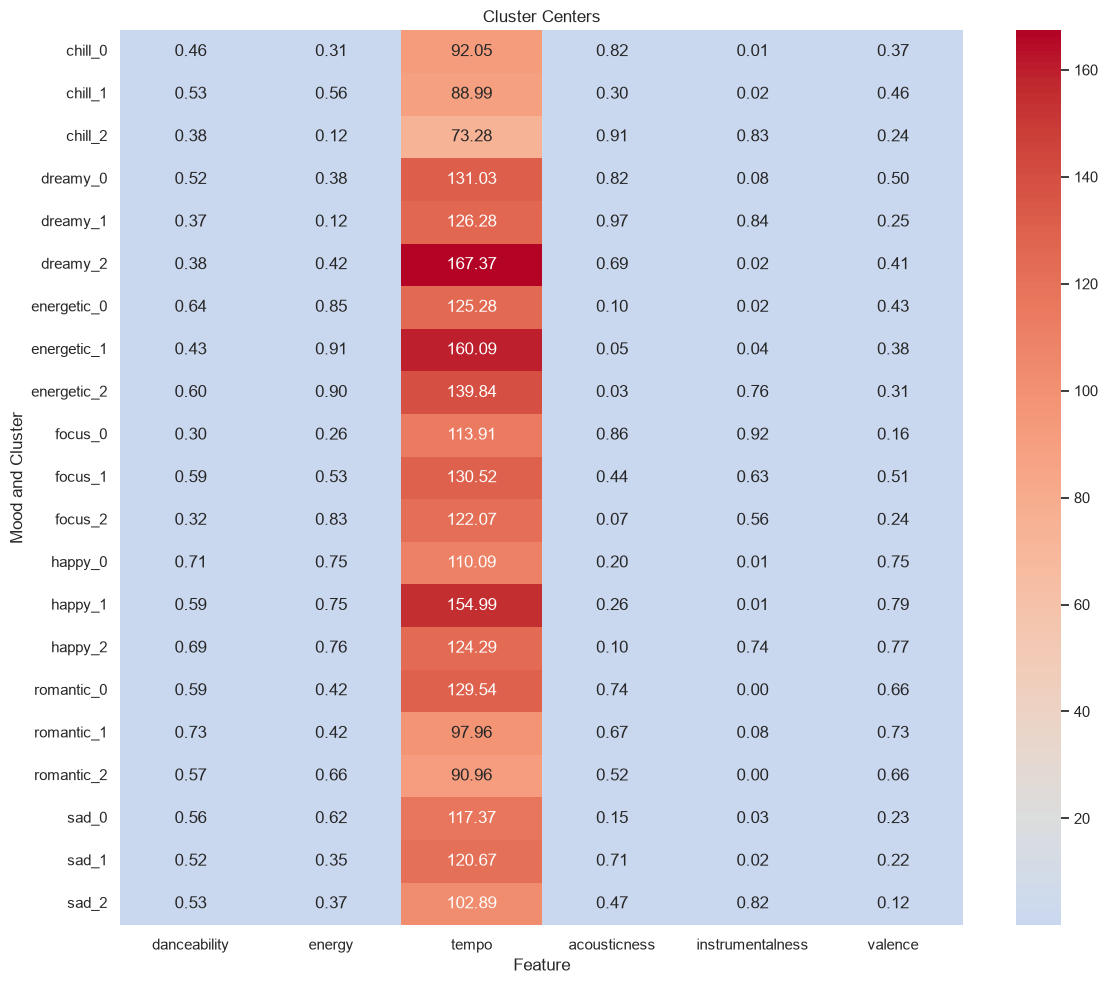

In [53]:
center_table = cluster_centers.copy()

center_table["mood_cluster"] = center_table["mood"] + "_" + center_table["cluster"].astype(str)

center_table = center_table.set_index("mood_cluster")[features]

plt.figure(figsize=(12, 10))

sns.heatmap(center_table, annot=True, fmt=".2f", cmap="coolwarm", center=center_table.values.mean())

plt.title("Cluster Centers")
plt.xlabel("Feature")
plt.ylabel("Mood and Cluster")
plt.tight_layout()
plt.show()

#### PCA

In [54]:
pca = PCA(n_components=2)

pca_values = pca.fit_transform(scaled_df[features])

df["pca_1"] = pca_values[:, 0]
df["pca_2"] = pca_values[:, 1]

print(pca.explained_variance_ratio_)
print("설명된 분산 비율:", pca.explained_variance_ratio_.sum())

[0.36110152 0.23510517]
설명된 분산 비율: 0.5962066993778534


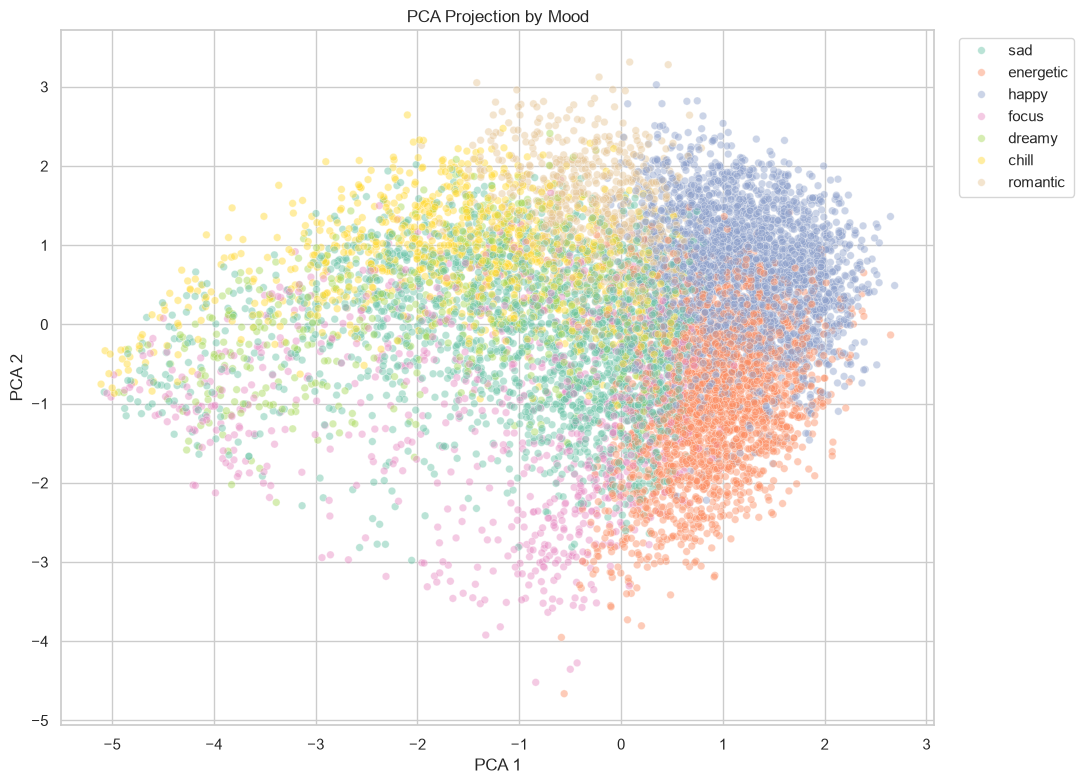

In [55]:
# 무드별 PCA 시각화
pca_sample = df.sample(min(10000, len(df)), random_state=42)

plt.figure(figsize=(11, 8))

sns.scatterplot(data=pca_sample, x="pca_1", y="pca_2", hue="mood", alpha=0.45, s=30, palette="Set2")

plt.title("PCA Projection by Mood")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

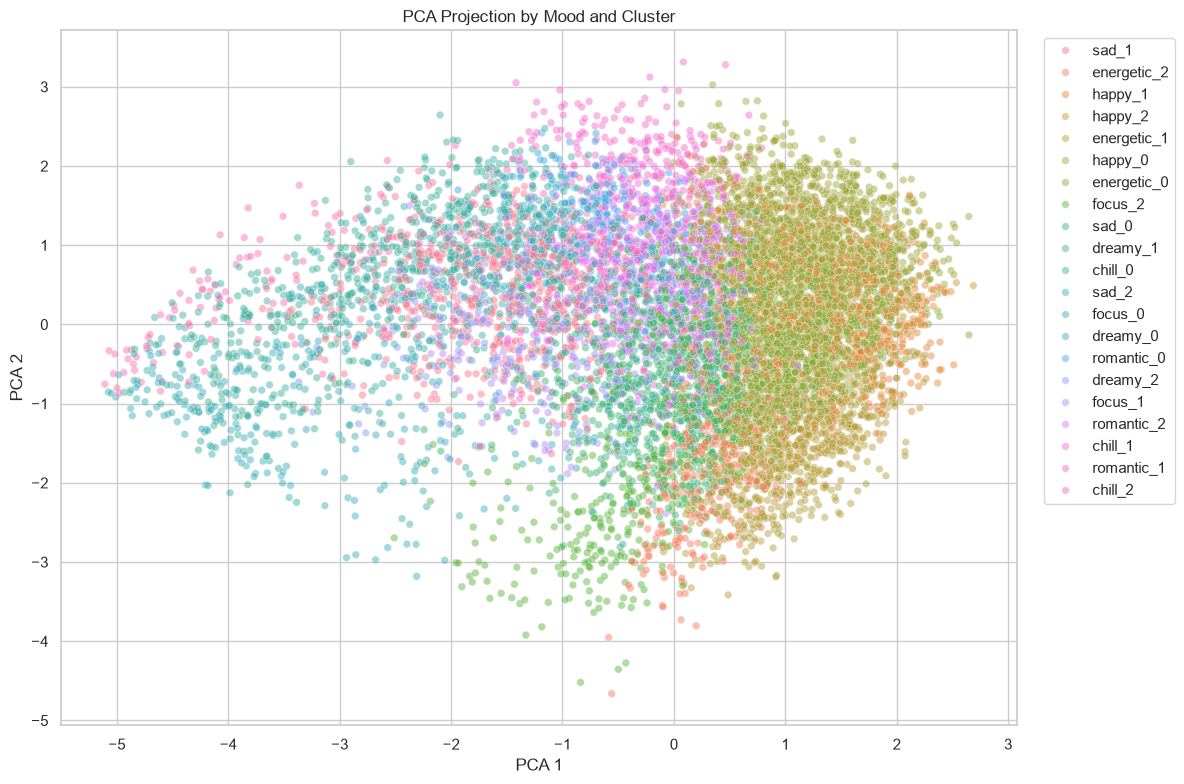

In [56]:
# 무드·군집별 PCA 시각화
plt.figure(figsize=(12, 8))

sns.scatterplot(data=pca_sample, x="pca_1", y="pca_2", hue="mood_cluster", alpha=0.45, s=30)

plt.title("PCA Projection by Mood and Cluster")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [57]:
# 무드별 Silhouette Score
final_scores = []

for mood in sorted(df["mood"].unique()):
    mood_index = df["mood"] == mood
    mood_data = scaled_df.loc[mood_index, features]
    labels = df.loc[mood_index, "cluster"]

    final_scores.append(
        {"mood": mood, "k": n_clusters, "silhouette": silhouette_score(mood_data, labels)}
    )

final_scores = pd.DataFrame(final_scores)

final_scores

,mood,k,silhouette
0,chill,3,0.309
1,dreamy,3,0.277
2,energetic,3,0.276
3,focus,3,0.260
4,happy,3,0.259
5,romantic,3,0.201
6,sad,3,0.248


In [58]:
final_scores["silhouette"].mean()

np.float64(0.26161027495729333)

In [59]:
model_dir = Path("../models")
report_dir = Path("../reports")
data_dir = Path("../data/processed")

model_dir.mkdir(exist_ok=True)
report_dir.mkdir(exist_ok=True)
data_dir.mkdir(exist_ok=True)

In [60]:
joblib.dump(scaler, model_dir / "scaler.pkl")

for mood, model in models.items():
    joblib.dump(model, model_dir / f"kmeans_{mood}.pkl")

In [61]:
df.to_csv(data_dir / "tracks_with_clusters.csv", index=False, encoding="utf-8-sig")

cluster_results.to_csv(report_dir / "cluster_results.csv", index=False, encoding="utf-8-sig")

cluster_counts.to_csv(report_dir / "cluster_counts.csv", index=False, encoding="utf-8-sig")

cluster_summary.to_csv(report_dir / "cluster_summary.csv", encoding="utf-8-sig")

cluster_centers.to_csv(report_dir / "cluster_centers.csv", index=False, encoding="utf-8-sig")

final_scores.to_csv(report_dir / "final_cluster_scores.csv", index=False)

## 군집화 결과

무드별로 데이터를 나눈 뒤 6개 Feature를 StandardScaler로 표준화하고 K-Means를 적용

K는 2~6을 비교했고 Elbow와 Silhouette Score를 같이 봤다. 서비스에서 무드마다 같은 구조를 쓰려고 K=3으로 정했다.

군집 번호는 무드마다 의미가 다르다. 번호가 아니라 군집별 Feature 평균을 보고 해석한다.